# Week 2: Classes, `__init__` and Inheritance
## One interface for every sensor on the vehicle

**Course:** AI for Aerospace & Mechanical Engineering (PhD) &nbsp;|&nbsp; **Block 0:** Python & OOP crash course

> **Provenance:** new content. The instructor's PDFs do not cover Python OOP, so the
> explanations are rewritten from (not copied from)
> [W3Schools Python Classes](https://www.w3schools.com/python/python_classes.asp),
> [W3Schools `__init__()`](https://www.w3schools.com/python/python_class_init.asp),
> [W3Schools Class Properties](https://www.w3schools.com/python/python_class_properties.asp),
> [W3Schools Inheritance](https://www.w3schools.com/python/python_inheritance.asp),
> [W3Schools Polymorphism](https://www.w3schools.com/python/python_polymorphism.asp),
> [GeeksforGeeks class vs instance variables](https://www.geeksforgeeks.org/python/g-fact-34-class-or-static-variables-in-python/),
> [GeeksforGeeks `super()`](https://www.geeksforgeeks.org/python/python-super/),
> [GeeksforGeeks `property()`](https://www.geeksforgeeks.org/python/python-property-function/),
> [GeeksforGeeks Abstract Classes](https://www.geeksforgeeks.org/python/abstract-classes-in-python/),
> [GeeksforGeeks dataclasses](https://www.geeksforgeeks.org/python/understanding-python-dataclasses/) and
> [GeeksforGeeks Getting Started with Pytest](https://www.geeksforgeeks.org/python/getting-started-with-pytest/).
> The ISA pressure-altitude model is adapted from Anderson, *Introduction to Flight*, Ch. 3.

<div dir="rtl">

**خلاصه‌ی فارسی:** ربات آزمایشی ما سه حسگر دارد (IMU، LiDAR و GPS) و هر کدام قالب داده‌ی خودش را دارد. کد رویه‌ای با چند `if/elif` برای هر نوع حسگر سریع شکننده می‌شود. در این آزمایشگاه یاد می‌گیریم با کلاس، `__init__`، ویژگی (property)، وراثت و کلاس پایه‌ی انتزاعی (ABC) یک «رابط مشترک» بسازیم تا هر حسگر جدید فقط با نوشتن یک زیرکلاس اضافه شود.

</div>

**How to use this notebook:** run cells top to bottom (*Restart & Run All* must work).
Cells tagged `exercise` contain `# TODO`: fill them in. A `[ ]` line means "not done yet";
`[x]` means your answer matches.

## 0. The problem: three sensors, three formats, one robot

Our test vehicle (a small UAV on the ground, or a wheeled robot) carries:

| Sensor | Raw sample | What preprocessing means |
|--------|------------|--------------------------|
| IMU | 6 numbers: accel x, y, z [m/s²], gyro x, y, z [deg/s] | remove biases; reject saturated samples |
| LiDAR | 16 ranges [m], 0.0 or `inf` when no echo | mark beams without echo as NaN; reject blind scans |
| GPS | latitude, longitude [deg], altitude [m], HDOP | convert to local metres; reject poor fixes |

Every later module of the course (lane detection, obstacle detection, the controller)
will consume these sensors. The question for today: **how do we write the code so that
adding a fourth sensor next month does not mean editing every function we own?**

Below is the "obvious" procedural version. Read it before running it.

In [1]:
from __future__ import annotations

import math
import subprocess
import sys
from abc import ABC, abstractmethod
from dataclasses import FrozenInstanceError, dataclass
from pathlib import Path
from typing import ClassVar, Final

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repo_root(start: Path) -> Path:
    """Walk up from ``start`` until the folder that contains ``src/aerospace_ai``."""
    for folder in (start, *start.parents):
        if (folder / "src" / "aerospace_ai").is_dir():
            return folder
    raise FileNotFoundError("Open this notebook from inside the course repository.")


REPO_ROOT: Final[Path] = find_repo_root(Path.cwd())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

FLIGHT_LOG: Final[Path] = REPO_ROOT / "data" / "sample" / "week01_uav_flight_log.csv"
G0: Final[float] = 9.80665              # standard gravity [m/s^2]
ISA_P0_PA: Final[float] = 101_325.0     # ISA sea-level pressure [Pa]
ISA_T0_K: Final[float] = 288.15         # ISA sea-level temperature [K]
ISA_LAPSE_K_PER_M: Final[float] = 0.0065
ISA_EXPONENT: Final[float] = 0.190263   # R * L / g0 for dry air
GROUND_END_S: Final[float] = 25.0       # the UAV is parked before this time [s]


def check(name: str, value: object, expected: float, tol: float) -> None:
    """Print a pass mark if ``value`` is within ``tol`` of ``expected``.

    A value of None means the exercise has not been attempted yet.
    """
    if value is None:
        print(f"[ ] {name}: not done yet")
        return
    assert abs(float(value) - expected) <= tol, f"{name}: got {value}, expected ~{expected}"
    print(f"[x] {name} = {float(value):.6g}")


print("Repository root found:", REPO_ROOT.name)

Repository root found: AI_ML_Classrom


In [2]:
# The procedural version: one function per job, an if/elif chain inside each.
IMU_BIAS = [0.1, -0.05, 0.2, 0.8, -0.3, 0.1]


def preprocess(sensor_type: str, data: list[float]) -> list[float]:
    """Preprocess a raw sample of any sensor (procedural style)."""
    if sensor_type == "imu":
        return [x - b for x, b in zip(data, IMU_BIAS)]
    elif sensor_type == "lidar":
        return [r if 0.15 <= r <= 12.0 else float("nan") for r in data]
    elif sensor_type == "gps":
        return data  # TODO someday: convert to metres
    return data  # unknown sensor: silently passes through


print(preprocess("imu", [0.35, -0.05, 10.05, 0.8, -0.3, 2.1]))
print(preprocess("IMU", [0.35, -0.05, 10.05, 0.8, -0.3, 2.1]))  # typo: no error, no bias removed
print(preprocess("imu", [0.35, -0.05]))                          # wrong length: no error either

[0.24999999999999997, 0.0, 9.850000000000001, 0.0, 0.0, 2.0]
[0.35, -0.05, 10.05, 0.8, -0.3, 2.1]
[0.24999999999999997, 0.0]


**What went wrong?**

1. `"IMU"` instead of `"imu"` falls through the chain: biased data flows on, **silently**.
2. A 2-value "IMU sample" is accepted: `zip` stops at the shorter list.
3. The bias lives in a global; two IMUs with different biases are impossible.
4. Adding a barometer means editing `preprocess`, `validate`, `plot`, `to_frame`, ...
   every function that has the chain.

The fix is to bundle **data** (bias, rate, buffer) with the **behaviour** that uses it
(validate, preprocess) in one object, and to let each sensor type supply its own
behaviour behind a shared interface. That is object-oriented programming.

## 1. Classes and objects: a first barometer

A *class* is a blueprint; an *object* (instance) is one thing built from it. `__init__`
runs automatically when an object is created and stores its attributes on `self`
(the object being built). A *method* is a function defined in the class; Python passes
the object as its first argument, `self`.

**Worked Example 1 (by hand first): ISA pressure altitude.** In the troposphere the
International Standard Atmosphere gives

$$h = \frac{T_0}{L}\left[1 - \left(\frac{p}{p_{\text{ref}}}\right)^{R L / g_0}\right],
\qquad \frac{T_0}{L} = \frac{288.15}{0.0065} = 44\,330.8\ \text{m},\quad \frac{R L}{g_0} = 0.190263 .$$

For $p = 95\,000$ Pa and $p_{\text{ref}} = 101\,325$ Pa:

* $p/p_{\text{ref}} = 0.937577$, $\ \ln(0.937577) = -0.064457$
* $0.190263 \times (-0.064457) = -0.012264 \Rightarrow (p/p_{\text{ref}})^{0.190263} = e^{-0.012264} = 0.987811$
* $h = 44\,330.8 \times (1 - 0.987811) = 44\,330.8 \times 0.012189 = 540.3$ m

In [3]:
class SimpleBarometer:
    """A first class: stores its configuration and converts pressure to altitude."""

    def __init__(self, sensor_id: str, reference_pressure_pa: float = ISA_P0_PA) -> None:
        """Store the sensor's name and the pressure that corresponds to 0 m."""
        self.sensor_id = sensor_id
        self.reference_pressure_pa = reference_pressure_pa

    def altitude_m(self, pressure_pa: float) -> float:
        """Return ISA pressure altitude above the reference level."""
        ratio = pressure_pa / self.reference_pressure_pa
        return ISA_T0_K / ISA_LAPSE_K_PER_M * (1.0 - ratio**ISA_EXPONENT)


baro = SimpleBarometer("baro0")          # __init__ runs here
print(type(baro).__name__, baro.sensor_id)
print(f"h(95 000 Pa) = {baro.altitude_m(95_000.0):.1f} m")
assert math.isclose(baro.altitude_m(95_000.0), 540.34, abs_tol=0.01)
print(baro)                              # default repr: not very helpful (fixed in Section 6)

SimpleBarometer baro0
h(95 000 Pa) = 540.3 m


**Exercise 1.1.** Before take-off at an airfield the tower reports QNH = 100 500 Pa. Create a
second barometer object `baro_qnh` that uses it as reference, and compute the altitude for
95 000 Pa. By hand: $(95\,000/100\,500)^{0.190263} = 0.98935$, so $h \approx 472$ m.
Two objects, one class, different state.

In [4]:
baro_qnh = SimpleBarometer("baro_qnh", reference_pressure_pa=100_500.0)
h_qnh = baro_qnh.altitude_m(95_000.0)

check("Exercise 1.1 altitude", h_qnh, 472.17, 0.01)

[x] Exercise 1.1 altitude = 472.168


## 2. Class attributes vs instance attributes (a classic bug)

An attribute assigned in the class body belongs to the **class** and is shared by every
object. An attribute assigned on `self` belongs to **one object**. Sharing is right for
constants (the channel names of every IMU are the same) and wrong for state (each IMU has
its own readings). Run the cell and explain the output before reading on.

In [5]:
class LeakySensor:
    """Deliberately wrong: the reading list is a class attribute."""

    readings: list[float] = []          # shared by ALL LeakySensor objects

    def __init__(self, sensor_id: str) -> None:
        self.sensor_id = sensor_id

    def add(self, value: float) -> None:
        self.readings.append(value)     # mutates the shared list


imu_a, imu_b = LeakySensor("a"), LeakySensor("b")
imu_a.add(1.0)
imu_a.add(2.0)
print("imu_b readings:", imu_b.readings, "<- imu_b never received a sample!")
print("same list object:", imu_a.readings is imu_b.readings)

imu_b readings: [1.0, 2.0] <- imu_b never received a sample!
same list object: True


`self.readings.append(...)` first looks for `readings` on the object, does not find it, then
finds the **class** attribute and mutates it. Rule: *mutable state goes in `__init__`*.

**Exercise 2.1.** Fix the class so each object owns its list. Keep `CHANNEL` as a class
attribute (a constant shared by every object is fine).

In [6]:
class FixedSensor:
    """Each object owns its readings; CHANNEL is a shared constant."""

    CHANNEL: ClassVar[str] = "value"

    def __init__(self, sensor_id: str) -> None:
        self.sensor_id = sensor_id
        self.readings: list[float] = []

    def add(self, value: float) -> None:
        self.readings.append(value)


try:
    fa, fb = FixedSensor("a"), FixedSensor("b")
    fa.add(1.0)
    check("Exercise 2.1 readings of b", len(fb.readings), 0, 0)
    assert fa.readings is not fb.readings and FixedSensor.CHANNEL == fa.CHANNEL
except AttributeError:
    print("[ ] Exercise 2.1: not done yet")

[x] Exercise 2.1 readings of b = 0


## 3. Properties: attributes that check themselves

A sampling rate of `-50` Hz or `0` Hz must never enter the system (we will divide by it).
A **property** looks like an attribute from outside (`imu.rate_hz = 100`) but runs a
method: the *getter* when read, the *setter* when assigned. Store the real value in a
"private" attribute with a leading underscore (`_rate_hz`); that underscore is a
convention meaning "not part of the public interface".

A property **without** a setter is read-only: perfect for a sensor ID that must never change.

In [7]:
class RatedSensor:
    """A sensor whose id is read-only and whose rate is validated."""

    def __init__(self, sensor_id: str, rate_hz: float) -> None:
        self._sensor_id = sensor_id
        self.rate_hz = rate_hz              # goes through the setter below

    @property
    def sensor_id(self) -> str:
        """Return the identifier (no setter: read-only)."""
        return self._sensor_id

    @property
    def rate_hz(self) -> float:
        """Return the sampling rate in Hz."""
        return self._rate_hz

    @rate_hz.setter
    def rate_hz(self, value: float) -> None:
        if not (math.isfinite(value) and value > 0):
            raise ValueError(f"rate_hz must be positive and finite, got {value}")
        self._rate_hz = float(value)


s = RatedSensor("imu0", 50.0)
s.rate_hz = 100.0
print("rate:", s.rate_hz)
for bad_action in (lambda: setattr(s, "rate_hz", 0.0), lambda: setattr(s, "sensor_id", "x")):
    try:
        bad_action()
    except (ValueError, AttributeError) as err:
        print(f"refused: {type(err).__name__}: {err}")

rate: 100.0
refused: ValueError: rate_hz must be positive and finite, got 0.0
refused: AttributeError: property 'sensor_id' of 'RatedSensor' object has no setter


**Exercise 3.1.** Add a read-only property `period_s` (= 1 / rate) to a subclass of
`RatedSensor`. For 50 Hz it must return 0.02 s, and it must follow later changes of
`rate_hz` automatically (that is the advantage over storing it in `__init__`).

In [8]:
class TimedSensor(RatedSensor):
    """RatedSensor plus a derived, read-only sampling period."""

    @property
    def period_s(self) -> float:
        """Return the nominal time between samples."""
        return 1.0 / self.rate_hz


t_sensor = TimedSensor("imu0", 50.0)
period_50 = getattr(t_sensor, "period_s", None)
t_sensor.rate_hz = 200.0
period_200 = getattr(t_sensor, "period_s", None)
check("Exercise 3.1 period at 50 Hz", period_50, 0.02, 1e-12)
check("Exercise 3.1 period at 200 Hz", period_200, 0.005, 1e-12)

[x] Exercise 3.1 period at 50 Hz = 0.02
[x] Exercise 3.1 period at 200 Hz = 0.005


## 4. Inheritance and `super()`

`class TimedSensor(RatedSensor)` above already used **inheritance**: the child class gets
every method and property of the parent and adds or *overrides* some. When a child needs
its own `__init__`, it must still let the parent initialise the parent's part. That is what
`super().__init__(...)` does: call the parent's version without naming the parent.

Below, a generic `Sensor` owns what every sensor has (id, rate, readings, `add_reading`),
and `Barometer` only adds what is special about barometers.

In [9]:
class Sensor(RatedSensor):
    """Generic sensor (version 1): stores preprocessed readings."""

    def __init__(self, sensor_id: str, rate_hz: float) -> None:
        super().__init__(sensor_id, rate_hz)     # id and validated rate
        self.readings: list[tuple[float, list[float]]] = []

    def preprocess(self, raw: list[float]) -> list[float]:
        """Default: no processing. Subclasses override this."""
        return list(raw)

    def add_reading(self, timestamp: float, raw: list[float]) -> None:
        """Preprocess and store one sample."""
        self.readings.append((timestamp, self.preprocess(raw)))


class Barometer(Sensor):
    """Barometer: raw pressure in, altitude out."""

    def __init__(self, sensor_id: str, rate_hz: float, reference_pressure_pa: float = ISA_P0_PA) -> None:
        super().__init__(sensor_id, rate_hz)     # everything a Sensor has ...
        self.reference_pressure_pa = reference_pressure_pa   # ... plus this

    def preprocess(self, raw: list[float]) -> list[float]:   # override
        ratio = raw[0] / self.reference_pressure_pa
        return [ISA_T0_K / ISA_LAPSE_K_PER_M * (1.0 - ratio**ISA_EXPONENT)]


b1 = Barometer("baro0", 25.0)
b1.add_reading(0.0, [95_000.0])
print(b1.readings, "| rate (inherited property):", b1.rate_hz)
print("isinstance(b1, Sensor):", isinstance(b1, Sensor))
print("method resolution order:", [c.__name__ for c in Barometer.__mro__])

[(0.0, [540.3368114807682])] | rate (inherited property): 25.0
isinstance(b1, Sensor): True
method resolution order: ['Barometer', 'Sensor', 'RatedSensor', 'object']


The **method resolution order** (MRO) is the list Python searches, left to right, when you
call `b1.preprocess`: it finds `Barometer.preprocess` first. `b1.rate_hz` is not defined in
`Barometer` or `Sensor`, so the search continues to `RatedSensor`.

## 5. Abstract base classes: make the interface a contract

Version 1 has a weakness: `Sensor("x", 1.0)` works, and its `preprocess` silently does
nothing; a subclass that forgets to override `preprocess` (or misspells it `pre_process`)
also passes silently. That is the procedural bug from Section 0 again.

An **abstract base class** (ABC) states "every sensor *must* provide `validate` and
`preprocess`". Python then refuses to create an object of any class that has not
implemented them, at construction time, long before a flight.

In [10]:
class AbstractSensor(ABC):
    """The contract: concrete sensors must implement validate and preprocess."""

    @abstractmethod
    def validate(self, raw: np.ndarray) -> bool:
        """Return True if the raw sample is plausible."""

    @abstractmethod
    def preprocess(self, raw: np.ndarray) -> np.ndarray:
        """Convert a valid raw sample to engineering units."""


class ForgetfulBarometer(AbstractSensor):
    def pre_process(self, raw: np.ndarray) -> np.ndarray:   # typo!
        return raw

    def validate(self, raw: np.ndarray) -> bool:
        return True


for cls in (AbstractSensor, ForgetfulBarometer):
    try:
        cls()
    except TypeError as err:
        print(f"{cls.__name__}: {err}")

AbstractSensor: Can't instantiate abstract class AbstractSensor with abstract methods preprocess, validate
ForgetfulBarometer: Can't instantiate abstract class ForgetfulBarometer with abstract method preprocess


## 6. Dataclasses: records without boilerplate

Each stored sample needs a timestamp, values, the sensor id and a validity flag. Written by
hand, a good record class needs `__init__`, `__repr__` (readable printing) and `__eq__`
(compare by value). `@dataclass` writes all three from the annotated fields.
`frozen=True` makes objects immutable (a logged measurement must never change) and
hashable; `slots=True` drops the per-object `__dict__`, saving memory for 100 000 readings.

In [11]:
class ManualReading:
    """The same record written by hand: 15 lines of boilerplate."""

    def __init__(self, timestamp: float, values: tuple[float, ...], sensor_id: str, is_valid: bool = True) -> None:
        self.timestamp = timestamp
        self.values = values
        self.sensor_id = sensor_id
        self.is_valid = is_valid

    def __repr__(self) -> str:
        return f"ManualReading(timestamp={self.timestamp}, values={self.values}, sensor_id={self.sensor_id!r}, is_valid={self.is_valid})"

    def __eq__(self, other: object) -> bool:
        if not isinstance(other, ManualReading):
            return NotImplemented
        return (self.timestamp, self.values, self.sensor_id, self.is_valid) == (
            other.timestamp, other.values, other.sensor_id, other.is_valid)


@dataclass(frozen=True, slots=True)
class Reading:
    """The same record as a dataclass."""

    timestamp: float
    values: tuple[float, ...]
    sensor_id: str
    is_valid: bool = True


r1, r2 = Reading(0.0, (9.81,), "imu0"), Reading(0.0, (9.81,), "imu0")
print(r1)
print("equal by value:", r1 == r2, "| same object:", r1 is r2)
try:
    r1.timestamp = 5.0
except FrozenInstanceError as err:
    print("immutable:", type(err).__name__)
print("has __dict__:", hasattr(r1, "__dict__"))

Reading(timestamp=0.0, values=(9.81,), sensor_id='imu0', is_valid=True)
equal by value: True | same object: False
immutable: FrozenInstanceError
has __dict__: False


Why is `values` a `tuple` and not a NumPy array? A tuple is immutable and compares with `==`
element by element; `array == array` returns an *array*, which breaks the generated `__eq__`
and `hash`. Convert to an array only when you compute (`np.asarray(r.values)`).

## 7. The course library: `aerospace_ai.sensors`

Sections 1 to 6 are combined in `src/aerospace_ai/sensors.py`, which the rest of the course
imports. Its design is the **template method** pattern: `BaseSensor.add_reading` fixes the
algorithm once, and each subclass fills in two steps.

```
add_reading(t, raw)
  1. check shape  (len(raw) == n_channels)       BaseSensor
  2. check time   (t > previous timestamp)        BaseSensor
  3. validate(raw)            -> bool             subclass
  4. preprocess(raw) if valid -> values           subclass
  5. store SensorReading(t, values, id, valid)    BaseSensor
```

Invalid samples are stored *unprocessed* with `is_valid=False` (useful for diagnosis) and are
excluded from `to_array()`.

**Worked Example 2 (by hand first): IMU bias removal and validation.** An IMU is configured
for ±4 g (full scale $4 \times 9.80665 = 39.23$ m/s²). Calibration gave accelerometer bias
$(0.10, -0.05, 0.20)$ m/s² and gyro bias $(0.8, -0.3, 0.1)$ deg/s. Four raw samples arrive:

| # | raw $a_x, a_y, a_z$ | raw $g_x, g_y, g_z$ | valid? | preprocessed | $n$ |
|---|---------------------|---------------------|--------|--------------|-----|
| 1 | 0.35, −0.05, 10.05 | 0.8, −0.3, 2.1 | yes | (0.25, 0, 9.85), (0, 0, 2.0) | $\sqrt{0.25^2+9.85^2}/g_0 = 1.005$ |
| 2 | 0.10, NaN, 9.90 | 0.8, −0.3, 0.1 | **no**: NaN | stored raw | — |
| 3 | 0.10, 0.00, 39.50 | 0.8, −0.3, 0.1 | **no**: $\lvert a_z\rvert \ge 39.23$ (saturated) | stored raw | — |
| 4 | 1.30, −0.45, 19.80 | 0.8, 4.7, 0.1 | yes | (1.2, −0.4, 19.6), (0, 5.0, 0) | $19.641/g_0 = 2.003$ |

Sample 3 is the important one: a saturated accelerometer reports its full-scale value, not
the truth. The real acceleration was *at least* 4 g, and we do not know how much more.

In [12]:
from aerospace_ai.sensors import BarometerSensor, BaseSensor, IMUSensor, SensorReading

imu = IMUSensor(
    "imu0", rate_hz=50.0,
    accel_bias=(0.10, -0.05, 0.20), gyro_bias=(0.8, -0.3, 0.1),
    accel_range_mps2=4 * G0,
)
raw_samples = [
    (0.35, -0.05, 10.05, 0.8, -0.3, 2.1),
    (0.10, np.nan, 9.90, 0.8, -0.3, 0.1),
    (0.10, 0.00, 39.50, 0.8, -0.3, 0.1),
    (1.30, -0.45, 19.80, 0.8, 4.7, 0.1),
]
for k, raw in enumerate(raw_samples):
    reading = imu.add_reading(k * imu.period_s, raw)
    print(reading.is_valid, np.round(reading.values, 3))

print(imu)
print("load factor of valid samples:", np.round(imu.load_factor(), 3))
assert imu.n_rejected == 2
assert np.allclose(imu.load_factor(), [1.0047, 2.0028], atol=1e-4)
imu.to_frame()

True [0.25 0.   9.85 0.   0.   2.  ]
False [ 0.1  nan  9.9  0.8 -0.3  0.1]
False [ 0.1  0.  39.5  0.8 -0.3  0.1]
True [ 1.2 -0.4 19.6  0.   5.   0. ]
IMUSensor(sensor_id='imu0', rate_hz=50.0, readings=4, rejected=2)
load factor of valid samples: [1.005 2.003]


,timestamp,accel_x_mps2,accel_y_mps2,accel_z_mps2,gyro_x_dps,gyro_y_dps,gyro_z_dps,is_valid
0,0.00,0.25,0.0,9.85,0.0,0.0,2.0,True
1,0.02,0.10,NaN,9.90,0.8,-0.3,0.1,False
2,0.04,0.10,0.0,39.50,0.8,-0.3,0.1,False
3,0.06,1.20,-0.4,19.60,0.0,5.0,0.0,True


## 8. Polymorphism: one loop, many sensor types

*Polymorphism* means "same call, type-specific behaviour". The loop below never asks which
sensor it holds: it calls `add_reading`, `len` and `n_rejected`, which every `BaseSensor`
has. Adding a new sensor type needs **zero** changes here, which is exactly what the
procedural version could not do.

**Exercise 8.1.** Write `ThermometerSensor(BaseSensor)` for an outside-air temperature probe
that reports **kelvin**:

* `CHANNELS = ("temp_c",)` and `UNITS = ("degC",)`
* `validate`: finite and strictly between 200 K and 350 K
* `preprocess`: kelvin to degrees Celsius (subtract 273.15)

By hand: 288.15 K is 15.00 °C, 250.00 K is −23.15 °C, 400 K is rejected.

In [13]:
KELVIN_OFFSET: Final[float] = 273.15
MIN_AIR_TEMP_K: Final[float] = 200.0
MAX_AIR_TEMP_K: Final[float] = 350.0


class ThermometerSensor(BaseSensor):
    """Outside-air temperature probe: kelvin in, degrees Celsius out."""

    CHANNELS: ClassVar[tuple[str, ...]] = ("temp_c",)
    UNITS: ClassVar[tuple[str, ...]] = ("degC",)

    def validate(self, raw: np.ndarray) -> bool:
        """Accept finite temperatures inside the plausible air range."""
        return bool(np.isfinite(raw[0]) and MIN_AIR_TEMP_K < raw[0] < MAX_AIR_TEMP_K)

    def preprocess(self, raw: np.ndarray) -> np.ndarray:
        """Convert kelvin to degrees Celsius."""
        return raw - KELVIN_OFFSET


try:
    thermo = ThermometerSensor("oat0", 1.0)
    for k, kelvin in enumerate((288.15, 250.0, 400.0)):
        thermo.add_reading(float(k), [kelvin])
    temps = thermo.to_array()[:, 0]
    check("Exercise 8.1 first temperature", temps[0], 15.0, 1e-9)
    check("Exercise 8.1 second temperature", temps[1], -23.15, 1e-9)
    check("Exercise 8.1 rejected samples", thermo.n_rejected, 1, 0)
except TypeError as err:
    thermo = None
    print("[ ] Exercise 8.1: not done yet ->", err)

[x] Exercise 8.1 first temperature = 15
[x] Exercise 8.1 second temperature = -23.15
[x] Exercise 8.1 rejected samples = 1


In [14]:
# One loop over a mixed list: no if/elif on the sensor type anywhere.
suite: list[BaseSensor] = [imu, BarometerSensor("baro0", 25.0)]
if thermo is not None:
    suite.append(thermo)

for sensor in suite:
    print(f"{sensor.sensor_id:<6} {type(sensor).__name__:<18} channels={sensor.channel_names} "
          f"readings={len(sensor)} rejected={sensor.n_rejected}")

imu0   IMUSensor          channels=('accel_x_mps2', 'accel_y_mps2', 'accel_z_mps2', 'gyro_x_dps', 'gyro_y_dps', 'gyro_z_dps') readings=4 rejected=2
baro0  BarometerSensor    channels=('altitude_m',) readings=0 rejected=0
oat0   ThermometerSensor  channels=('temp_c',) readings=3 rejected=1


## 9. Back to the Week 1 flight log: an IMU object at work

The Week 1 log had three single-sample spikes of about +40 m/s² in `accel_z`. Suppose the
real IMU was configured for **±4 g**: a spike would hit full scale, and `validate` would
reject it as saturated, before any filtering. We also *calibrate* the biases from the
parked segment (t < 25 s), where the true specific force is $(0, 0, +g_0)$ and the true
angular rate is zero.

In [15]:
log = pd.read_csv(FLIGHT_LOG)
channels = list(IMUSensor.CHANNELS)          # the column names match the CSV

flight_imu = IMUSensor("imu_flight", rate_hz=50.0, accel_range_mps2=4 * G0)
flight_imu.calibrate(log.loc[log["time_s"] < GROUND_END_S, channels].to_numpy())
print("accel bias [m/s^2]:", np.round(flight_imu.accel_bias, 4))
print("gyro bias  [deg/s]:", np.round(flight_imu.gyro_bias, 4))

n_valid = flight_imu.add_readings(log["time_s"].to_numpy(), log[channels].to_numpy())
print(flight_imu, f"-> {n_valid} valid samples")

frame = flight_imu.to_frame()
print(frame.loc[~frame["is_valid"], ["timestamp", "accel_z_mps2"]])

accel bias [m/s^2]: [ 0.0006 -0.0013 -0.0001]
gyro bias  [deg/s]: [-0.0056 -0.0159 -0.0097]


IMUSensor(sensor_id='imu_flight', rate_hz=50.0, readings=14940, rejected=3) -> 14937 valid samples
      timestamp  accel_z_mps2
1565      31.30       49.7874
3334      66.68       50.3274
8950     180.20       49.8254


In [16]:
load_factor = flight_imu.load_factor()
t_valid = flight_imu.timestamps()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(log["time_s"], np.linalg.norm(log[channels[:3]].to_numpy(), axis=1) / G0,
        lw=0.5, color="0.6", label="raw log (spikes included)")
ax.plot(t_valid, load_factor, lw=0.8, color="tab:red", label="IMUSensor (saturated samples rejected)")
ax.axhline(2.0, ls="--", color="k", lw=0.8, label="2.0 g limit")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Load factor n [-]")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
print(f"peak load factor of valid samples: {load_factor.max():.2f} g")

peak load factor of valid samples: 1.81 g


Without any rolling median, validation alone brought the peak from about 5.1 g (a glitch)
to 1.81 g (the pull-up). In Week 1 the same answer needed a filter; here the *object knows
its own limits*.

## 10. Testing the class with `pytest`

A test is a function whose name starts with `test_` and which uses plain `assert`.
`pytest` finds and runs every such function in files named `test_*.py`, and reports which
failed and why. `pytest.raises` checks that an error *is* raised;
`@pytest.mark.parametrize` runs one test on several inputs; a `@pytest.fixture` builds a
fresh object for each test.

```python
@pytest.fixture
def imu() -> IMUSensor:
    return IMUSensor("imu0", 50.0, accel_bias=(0.1, -0.2, 0.3), gyro_bias=(0.5, 0.0, -0.5))

def test_imu_removes_bias(imu: IMUSensor) -> None:
    reading = imu.add_reading(0.0, [0.1, -0.2, 10.1, 1.5, 0.0, -0.5])
    np.testing.assert_allclose(reading.values, [0.0, 0.0, 9.8, 1.0, 0.0, 0.0])

@pytest.mark.parametrize("rate", [0.0, -5.0, math.nan])
def test_rate_must_be_positive(rate: float) -> None:
    with pytest.raises(ValueError):
        IMUSensor("imu0", rate)
```

These tests (and more) live in `tests/test_sensors.py`. Run them from a terminal with
`pytest`, or from here:

27 passed in 0.79s


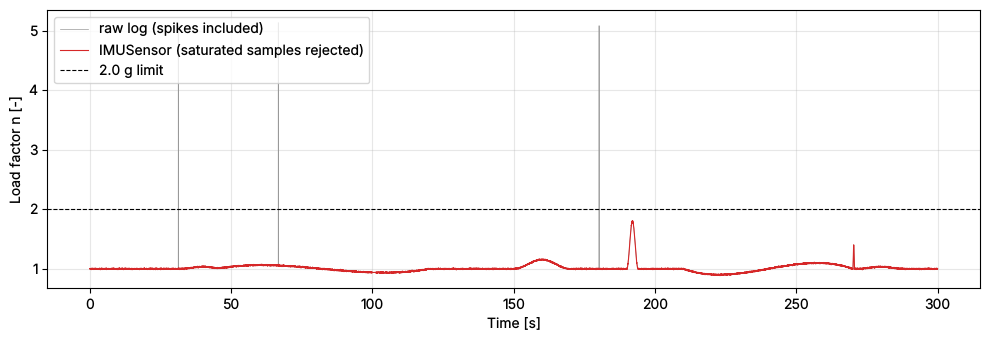

In [17]:
result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "-p", "no:warnings", "tests/test_sensors.py"],
    cwd=REPO_ROOT, capture_output=True, text=True,
)
print(result.stdout.strip().splitlines()[-1])
assert result.returncode == 0, result.stdout

**Exercise 10.1.** Write a test function `test_thermometer_rejects_hot_probe` for your
`ThermometerSensor`: a 400 K reading must be stored with `is_valid=False` and must not appear
in `to_array()`. In a notebook you can call the function directly; in Assignment 1 you will
put tests like this in a `test_*.py` file.

In [18]:
def test_thermometer_rejects_hot_probe() -> None:
    """A 400 K sample is stored as invalid and excluded from to_array()."""
    probe = ThermometerSensor("oat_test", 1.0)
    reading = probe.add_reading(0.0, [400.0])
    assert not reading.is_valid
    assert probe.n_rejected == 1
    assert probe.to_array().shape == (0, 1)
    assert len(probe) == 1


try:
    test_thermometer_rejects_hot_probe()
    print("[x] Exercise 10.1 test passed")
except (NotImplementedError, TypeError):
    print("[ ] Exercise 10.1: not done yet")

[x] Exercise 10.1 test passed


## 11. Final checks

The cell below verifies the worked examples and the flight-log result. It must pass
on every machine (this is the notebook's own test cell).

In [19]:
assert math.isclose(SimpleBarometer("b").altitude_m(95_000.0), 540.34, abs_tol=0.01)
assert LeakySensor("x").readings is LeakySensor("y").readings      # the bug, demonstrated
assert imu.n_rejected == 2 and np.isclose(imu.load_factor()[-1], 2.003, atol=1e-3)
assert flight_imu.n_rejected == 3
assert 1.75 < flight_imu.load_factor().max() < 1.85 < 2.0
print("All Week 2 checks passed.")

All Week 2 checks passed.


## What we now know how to do

* Bundle data and behaviour in a class; create objects with `__init__` and `self`.
* Tell class attributes (shared constants) from instance attributes (per-object state).
* Guard attributes with properties: validated setters, read-only and derived values.
* Reuse code through inheritance; extend a parent's `__init__` with `super()`.
* Turn an interface into a contract with an abstract base class.
* Write record types with `@dataclass(frozen=True, slots=True)`.
* Process a mixed list of sensors polymorphically, with no `if/elif` on types.
* Test a class with `pytest`: plain asserts, `raises`, `parametrize`, fixtures.

**Assignment 1** (`assignments/assignment01/`): implement `LidarSensor` and `GPSSensor`
on top of `BaseSensor`, plus your own pytest suite.
**Next week:** abstract classes in depth, typing, `__repr__`/`__eq__` and a composable
`DataPipeline` with typed stages.